# 90 · Questions

One section per question, each ending with a short written answer. Grain is `case_latest_T` (latest version, nullified removed) unless stated. Anything derived here follows the `_T` rule and lives in temp views or DataFrame columns ending in `_T`.

It reads a release folder (`RELEASE` in the first code cell, or the setting `OPEN_ALTIO_RELEASE`), read only. No release yet? Build one with `open-altio demo` (FDA's latest quarter) or `open-altio build` (every quarter FDA published).

Questions:
1. Who actually sends data to FAERS?

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from open_altio.faers.insights.cards.notebook import (
    SERIES,
    header,
    mark_years,
    setup,
    title,
)
from open_altio.faers.insights.source import connect

setup()
# The release folder this notebook reads; None reads $OPEN_ALTIO_RELEASE.
# No release yet? Build one with `open-altio demo` or `open-altio build`.
RELEASE = None
con = connect(RELEASE)  # read only; raw tables as demo_all, drug_all, ... and the derived _T tables


def q(sql):
    return con.execute(sql).fetchdf()

## Q1 · Who actually sends data to FAERS?

Three fields describe the chain from observation to FDA:

- `occp_cod` and RPSR say who **observed and reported** the event (consumer, physician, ...). That is the reporter, not the sender.
- `rept_cod` says by which **path** the case reached FDA: `DIR` means the reporter sent it straight to FDA through MedWatch; `EXP`, `PER`, `30DAY`, `5DAY` mean a company received it and forwarded it under its reporting obligations.
- `mfr_sndr` names the **sender**. For direct reports FDA fills in `FDA-CTU` (or nothing). In the FAERS era FDA has standardised the company names to a controlled list; in the legacy era the field holds whatever the company typed.
- `mfr_num` is the sender's own case identifier. In E2B format it is `country-organisation-number`, which tells you the originating safety database, not just the company name.

### 1a · Path: direct to FDA vs via a company

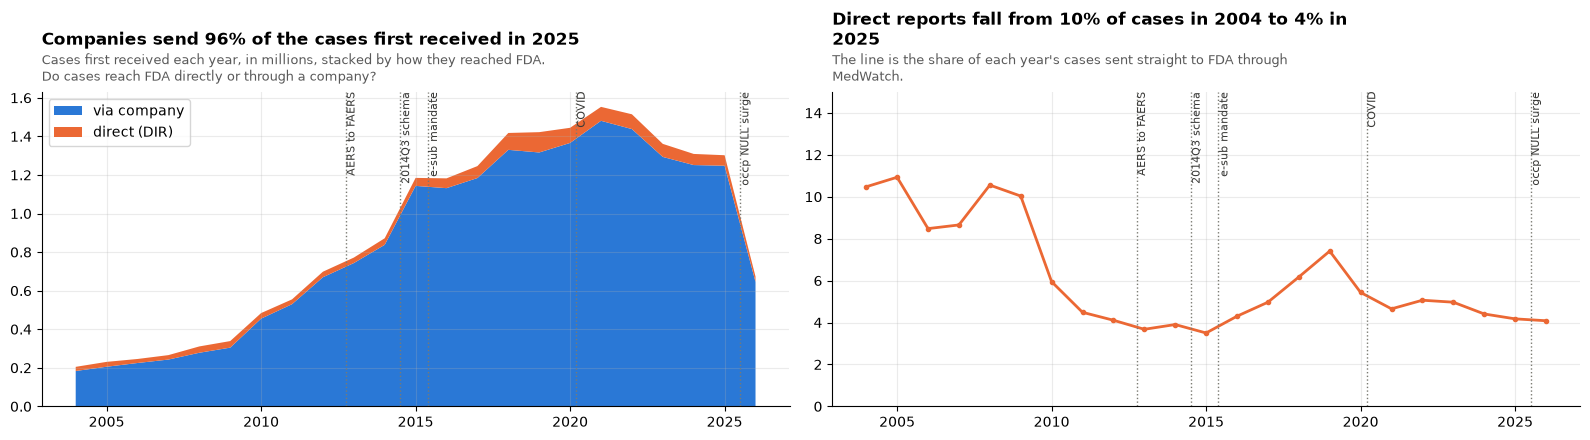

init_year_T,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
path_T,,,,,,,,,,,,,,,,,,,,,,,
via company,183547,205576,224953,242840,278093,304655,455115,529920,669695,743166,837751,1143308,1131532,1184038,1330259,1316615,1366049,1480796,1437927,1293514,1251297,1247918,645762
direct (DIR),21474,25224,20841,23007,32817,33971,28777,24896,28698,28367,34029,41477,50857,61908,87480,105320,78503,72246,76694,67643,57707,54371,27504


In [2]:
path = q("""select init_year_T, case when rept_cod='DIR' then 'direct (DIR)' when rept_cod in ('EXP','PER','30DAY','5DAY') then 'via company' else 'unknown' end path_T, count(*) n
from case_latest_T where init_year_T between 2004 and 2026 group by all order by 1""")
pp = path.pivot(index="init_year_T", columns="path_T", values="n").fillna(0)[
    ["via company", "direct (DIR)"]
]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 4.5))
a1.stackplot(
    pp.index,
    pp["via company"] / 1e6,
    pp["direct (DIR)"] / 1e6,
    labels=pp.columns,
    colors=[SERIES[0], SERIES[1]],
)
year = pp.index.max() - 1
direct = 100 * pp["direct (DIR)"] / pp.sum(axis=1)
title(
    a1,
    f"Companies send {100 - direct[year]:.0f}% of the cases first received in {year}",
    "Cases first received each year, in millions, stacked by how they reached FDA.",
    "Do cases reach FDA directly or through a company?",
)
a1.legend(loc="upper left")
mark_years(a1)
a2.plot(pp.index, 100 * pp["direct (DIR)"] / pp.sum(axis=1), color=SERIES[1], marker="o", ms=3)
a2.set_ylim(0, 15)
title(
    a2,
    f"Direct reports fall from {direct[2004]:.0f}% of cases in 2004 to {direct[year]:.0f}% in {year}",
    "The line is the share of each year's cases sent straight to FDA through MedWatch.",
)
mark_years(a2)
plt.tight_layout()
plt.show()
pp.astype(int).T

Well over 90% of cases enter through a company. The direct share was around 10% in the legacy years, fell to about 4% by 2013 and has stayed there apart from a bump in 2019. The sender population is therefore essentially the set of companies with reporting obligations, plus FDA itself for the direct channel.

### 1b · How many company senders, and how concentrated

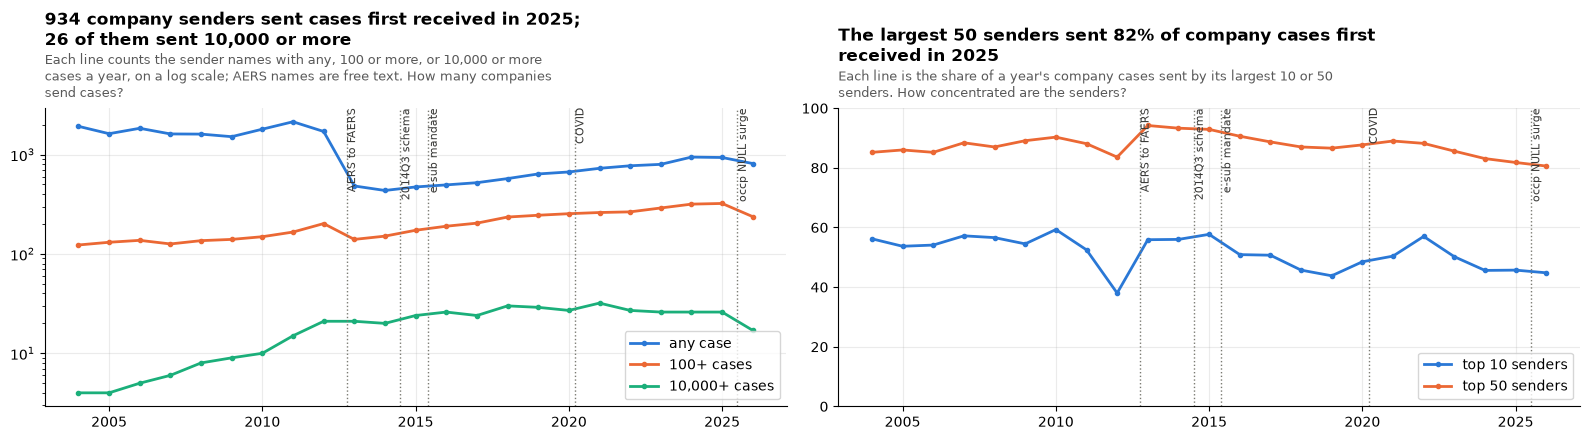

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22
init_year_T,2004.0,2005.0,2006.0,2007.0,2008.0,2009.0,2010.0,2011.0,2012.0,2013.0,2014.0,2015.0,2016.0,2017.0,2018.0,2019.0,2020.0,2021.0,2022.0,2023.0,2024.0,2025.0,2026.0
senders_any,1924.0,1621.0,1838.0,1612.0,1606.0,1513.0,1800.0,2138.0,1707.0,483.0,435.0,472.0,495.0,521.0,573.0,638.0,668.0,727.0,771.0,797.0,943.0,934.0,812.0
senders_100plus,123.0,131.0,137.0,126.0,136.0,140.0,149.0,166.0,202.0,140.0,151.0,173.0,190.0,204.0,235.0,245.0,254.0,261.0,265.0,290.0,317.0,322.0,237.0
senders_10k_plus,4.0,4.0,5.0,6.0,8.0,9.0,10.0,15.0,21.0,21.0,20.0,24.0,26.0,24.0,30.0,29.0,27.0,32.0,27.0,26.0,26.0,26.0,17.0
top10_pct,56.2,53.7,54.1,57.2,56.6,54.5,59.3,52.5,38.0,55.9,56.0,57.7,50.9,50.7,45.7,43.8,48.5,50.4,57.0,50.2,45.6,45.7,44.8
top50_pct,85.2,86.0,85.2,88.4,87.0,89.1,90.3,88.1,83.6,94.2,93.3,92.9,90.6,88.7,87.0,86.6,87.7,89.0,88.2,85.6,83.1,81.8,80.6


In [3]:
act = q("""with s as (select init_year_T, era_T, mfr_sndr, count(*) n from case_latest_T
  where rept_cod<>'DIR' and mfr_sndr is not null and init_year_T between 2004 and 2026 group by all),
r as (select *, row_number() over (partition by init_year_T order by n desc) rk, sum(n) over (partition by init_year_T) tot from s)
select init_year_T, count(*) senders_any, count(*) filter (where n>=100) senders_100plus, count(*) filter (where n>=10000) senders_10k_plus,
  round(100.0*sum(n) filter (where rk<=10)/max(tot),1) top10_pct, round(100.0*sum(n) filter (where rk<=50)/max(tot),1) top50_pct
from r group by 1 order by 1""")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 4.5))
a1.plot(act.init_year_T, act.senders_any, label="any case", marker="o", ms=3)
a1.plot(act.init_year_T, act.senders_100plus, label="100+ cases", marker="o", ms=3)
a1.plot(act.init_year_T, act.senders_10k_plus, label="10,000+ cases", marker="o", ms=3)
a1.set_yscale("log")
now = act[act.init_year_T == act.init_year_T.max() - 1].iloc[0]
title(
    a1,
    f"{now.senders_any:,.0f} company senders sent cases first received in {now.init_year_T:.0f}; "
    f"{now.senders_10k_plus:,.0f} of them sent 10,000 or more",
    "Each line counts the sender names with any, 100 or more, or 10,000 or more cases a year, on a "
    "log scale; AERS names are free text.",
    "How many companies send cases?",
)
a1.legend()
mark_years(a1)
a2.plot(act.init_year_T, act.top10_pct, label="top 10 senders", marker="o", ms=3)
a2.plot(act.init_year_T, act.top50_pct, label="top 50 senders", marker="o", ms=3)
a2.set_ylim(0, 100)
title(
    a2,
    f"The largest 50 senders sent {now.top50_pct:.0f}% of company cases first received in "
    f"{now.init_year_T:.0f}",
    "Each line is the share of a year's company cases sent by its largest 10 or 50 senders.",
    "How concentrated are the senders?",
)
a2.legend(loc="lower right")
mark_years(a2)
plt.tight_layout()
plt.show()
act.T

### 1c · The same few senders, year after year

Rows are the 30 largest FAERS-era senders; each cell is that sender's share of the year's company-path cases.

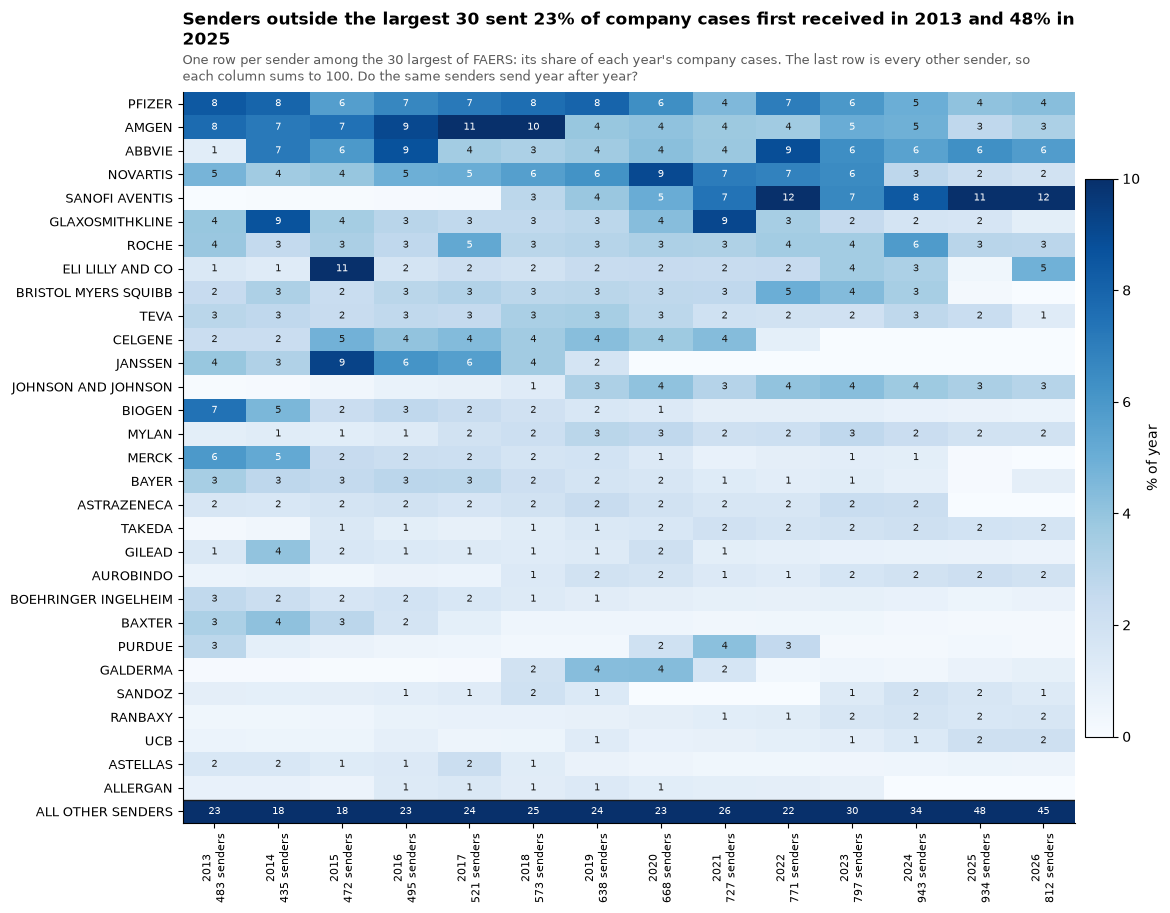

init_year_T,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
% from senders outside the top 30,22.6,18.37,17.62,23.38,23.82,25.42,23.93,22.51,25.53,22.26,29.74,33.64,48.42,44.93


In [4]:
sy = q("""with s as (select mfr_sndr, init_year_T, count(*) n from case_latest_T where era_T='faers' and rept_cod<>'DIR' and init_year_T between 2013 and 2026 group by all),
top as (select mfr_sndr from s group by 1 order by sum(n) desc limit 30),
tot as (select init_year_T, sum(n) tot, count(distinct mfr_sndr) senders from s group by 1)
select case when mfr_sndr in (select mfr_sndr from top) then mfr_sndr else 'ALL OTHER SENDERS' end sender_T, init_year_T, round(100.0*sum(n)/max(tot),2) pct
from s join tot using (init_year_T) group by 1,2""")
nsend = q(
    """select init_year_T, count(distinct mfr_sndr) senders from case_latest_T where era_T='faers' and rept_cod<>'DIR' and init_year_T between 2013 and 2026 group by 1 order by 1"""
)
m = sy.pivot(index="sender_T", columns="init_year_T", values="pct").fillna(0)
rest = m.loc[["ALL OTHER SENDERS"]]
m = m.drop(index="ALL OTHER SENDERS")
m = pd.concat(
    [m.loc[m.sum(axis=1).sort_values(ascending=False).index], rest]
)  # columns now sum to 100
fig, ax = plt.subplots(figsize=(12, 9.5))
im = ax.imshow(m.values, aspect="auto", cmap="Blues", vmin=0, vmax=10)
ax.set_yticks(range(len(m)))
ax.set_yticklabels(m.index, fontsize=9)
ax.set_xticks(range(len(m.columns)))
ax.set_xticklabels(
    [f"{y}\n{n} senders" for y, n in zip(m.columns, nsend.senders, strict=False)],
    rotation=90,
    fontsize=8,
)
ax.grid(False)
for i in range(len(m)):
    for j in range(len(m.columns)):
        v = m.values[i, j]
        if v >= 1:
            ax.text(
                j,
                i,
                f"{v:.0f}",
                ha="center",
                va="center",
                fontsize=7,
                color="white" if v > 5 else "#1a1a19",
            )
ax.axhline(len(m) - 1.5, color="#1a1a19", lw=1)
rest = m.loc["ALL OTHER SENDERS"]
title(
    ax,
    f"Senders outside the largest 30 sent {rest.iloc[0]:.0f}% of company cases first received in "
    f"{rest.index[0]} and {rest.iloc[-2]:.0f}% in {rest.index[-2]}",
    "One row per sender among the 30 largest of FAERS: its share of each year's company cases. The "
    "last row is every other sender, so each column sums to 100.",
    "Do the same senders send year after year?",
)
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.01, label="% of year")
plt.show()
m.loc["ALL OTHER SENDERS"].to_frame("% from senders outside the top 30").T

The last row grows from about 23% to 45 to 48% in 2025 and 2026. Part of that is real (Alexion, Novo Nordisk, Acadia, Celltrion and the generic houses gaining), but most of it is a naming artifact: from 2024Q4 several large senders appear under a second, longer spelling. FDA's controlled sender list is no longer stable, and the mapping toggles quarter by quarter.

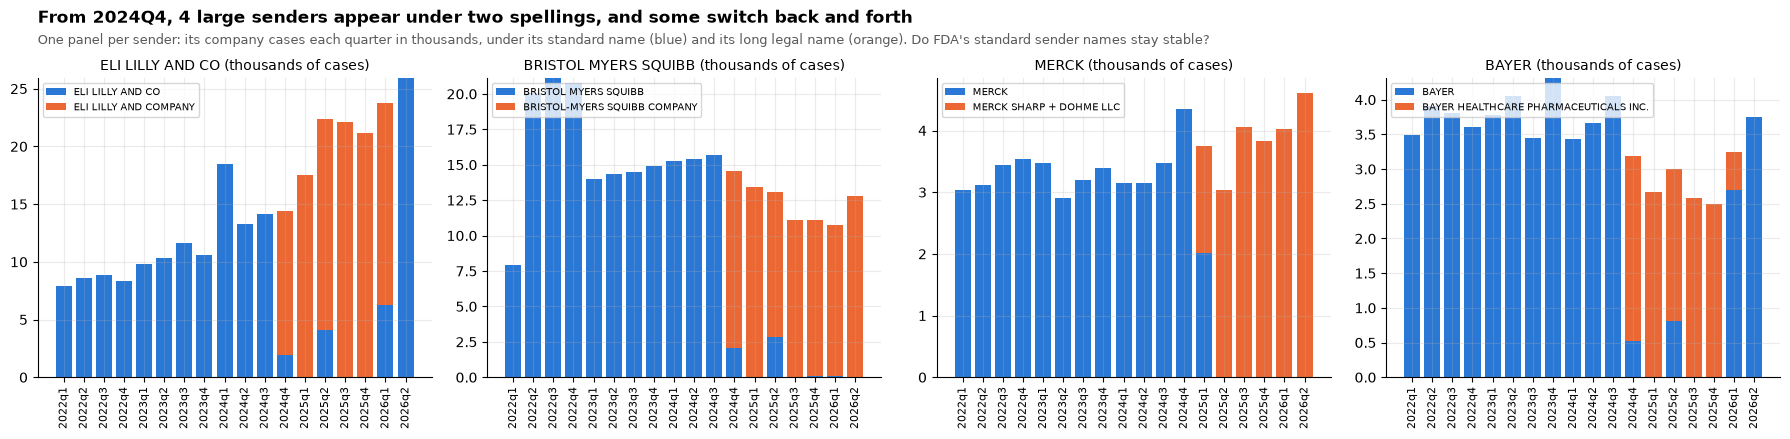

quarter_T,2022q1,2022q2,2022q3,2022q4,2023q1,2023q2,2023q3,2023q4,2024q1,2024q2,2024q3,2024q4,2025q1,2025q2,2025q3,2025q4,2026q1,2026q2
mfr_sndr,,,,,,,,,,,,,,,,,,
BAYER,3492,3914,3808,3601,3784,4056,3444,4308,3430,3662,4056,526,0,808,0,0,2693,3756
BAYER HEALTHCARE PHARMACEUTICALS INC.,0,0,0,0,0,0,0,0,0,0,0,2666,2664,2192,2578,2499,559,0
BRISTOL MYERS SQUIBB,7941,20054,21098,20784,13987,14316,14520,14938,15251,15425,15704,2072,0,2849,0,64,76,37
BRISTOL-MYERS SQUIBB COMPANY,0,0,0,0,0,0,0,0,0,0,0,12461,13440,10244,11084,11063,10677,12754
ELI LILLY AND CO,7937,8611,8900,8304,9790,10344,11607,10572,18514,13312,14105,1952,0,4110,0,0,6239,25898
ELI LILLY AND COMPANY,0,0,0,0,0,0,0,0,0,0,0,12453,17514,18238,22122,21152,17492,0
MERCK,3038,3124,3438,3537,3480,2901,3198,3385,3154,3145,3473,4344,2018,0,0,0,0,0
MERCK SHARP + DOHME LLC,0,0,0,0,0,0,0,0,0,0,0,0,1735,3035,4051,3835,4024,4615


In [5]:
pairs = [
    ("ELI LILLY AND CO", "ELI LILLY AND COMPANY"),
    ("BRISTOL MYERS SQUIBB", "BRISTOL-MYERS SQUIBB COMPANY"),
    ("MERCK", "MERCK SHARP + DOHME LLC"),
    ("BAYER", "BAYER HEALTHCARE PHARMACEUTICALS INC."),
]
names = [n for pr in pairs for n in pr]
sp = q(f"""select quarter_T, mfr_sndr, count(*) n from case_latest_T where era_T='faers' and rept_cod<>'DIR' and quarter_T >= '2022q1'
  and mfr_sndr in ({", ".join("'" + n + "'" for n in names)}) group by all order by 1""")
sp = sp.pivot(index="quarter_T", columns="mfr_sndr", values="n").fillna(0)
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharex=True)
for ax, (old, new) in zip(axes, pairs, strict=True):
    ax.bar(range(len(sp)), sp[old] / 1e3, width=0.8, color=SERIES[0], label=old)
    ax.bar(
        range(len(sp)), sp[new] / 1e3, bottom=sp[old] / 1e3, width=0.8, color=SERIES[1], label=new
    )
    ax.set_xticks(range(len(sp)))
    ax.set_xticklabels(sp.index, rotation=90, fontsize=8)
    ax.set_title(f"{old} (thousands of cases)", fontsize=10)
    ax.legend(fontsize=7, loc="upper left")
plt.tight_layout()
first_new = min(sp.index[sp[new] > 0][0] for _, new in pairs)
title(
    header(fig),
    f"From {first_new.upper()}, {len(pairs)} large senders appear under two spellings, and some "
    "switch back and forth",
    "One panel per sender: its company cases each quarter in thousands, under its standard name "
    "(blue) and its long legal name (orange).",
    "Do FDA's standard sender names stay stable?",
)
plt.show()
sp.T.astype(int)

### 1d · What each large sender sends

Senders differ in what they forward: the expedited vs periodic split, how consumer-heavy their reports are, how US-centred, and how often they follow up. These are the sender fingerprints that a comparator choice has to respect.

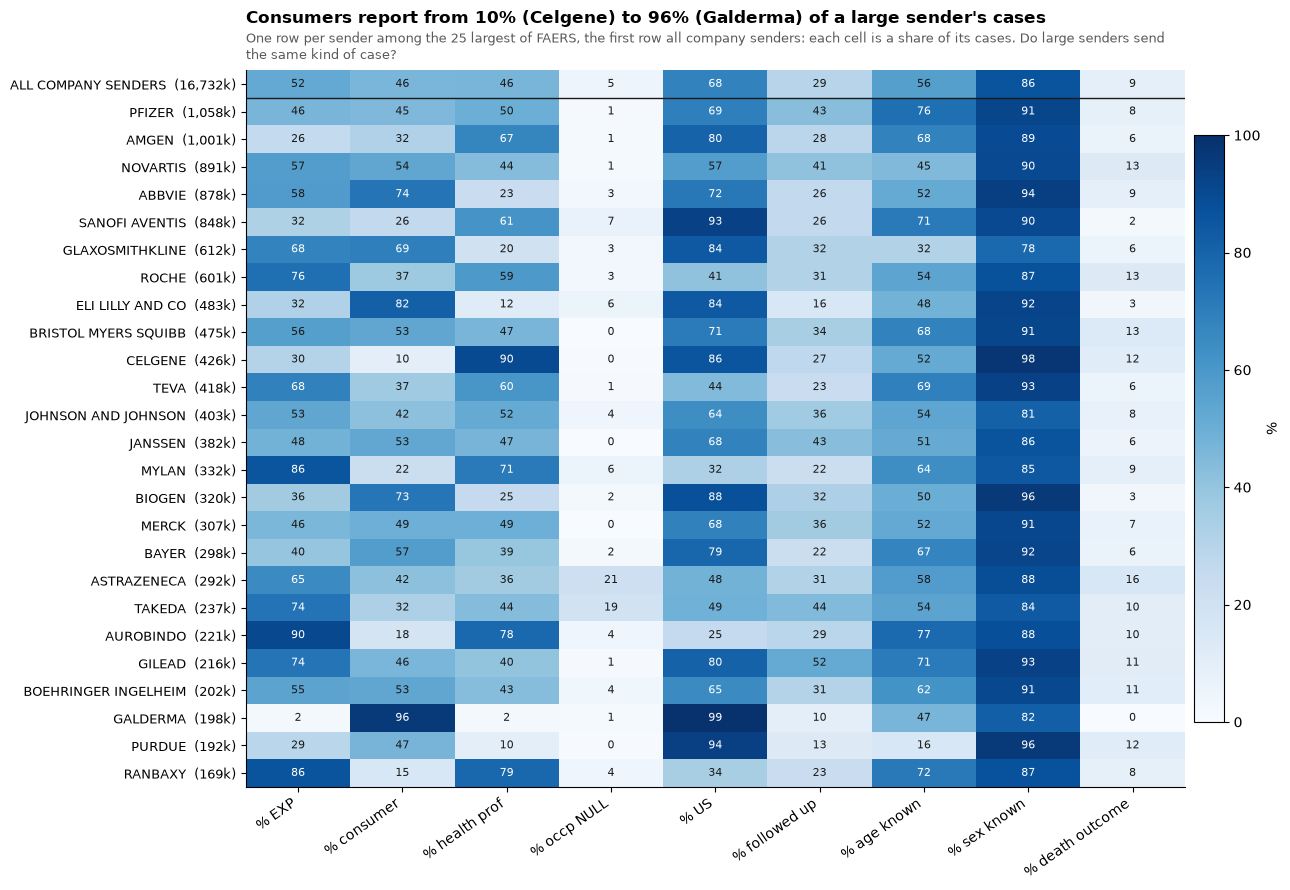

,cases,% EXP,% consumer,% health prof,% occp NULL,% US,% followed up,% age known,% sex known,% death outcome,drugs per case,reactions per case
mfr_sndr,,,,,,,,,,,,
ALL COMPANY SENDERS,16731893,52.3,46.1,46.5,4.7,68.0,29.3,56.3,86.3,8.9,3.7,2.9
PFIZER,1058397,46.5,45.2,49.7,1.1,69.3,42.8,75.5,91.2,8.3,3.5,2.9
AMGEN,1000900,25.5,31.7,67.0,1.3,80.4,28.5,68.3,89.3,6.5,2.2,2.4
NOVARTIS,890888,57.4,53.5,43.7,1.4,57.2,40.8,44.7,90.1,12.6,3.3,3.6
ABBVIE,877547,57.9,73.7,23.0,2.7,72.2,25.9,51.6,93.8,8.8,3.3,3.2
SANOFI AVENTIS,847594,32.1,25.9,61.3,6.8,93.2,26.1,71.2,90.0,2.3,2.5,2.5
GLAXOSMITHKLINE,611799,67.8,69.2,19.8,2.7,84.0,31.6,31.5,77.8,6.0,3.8,2.5
ROCHE,600696,75.7,37.3,59.2,2.8,41.0,31.3,54.1,86.9,13.2,4.3,3.3
ELI LILLY AND CO,483387,32.0,81.6,12.0,5.9,84.1,15.5,47.7,91.9,3.2,2.8,2.7


In [6]:
prof = q("""with c as (select * from case_latest_T where era_T='faers' and rept_cod<>'DIR'),
top as (select mfr_sndr from c group by 1 order by count(*) desc limit 25),
dr as (select era_T, primaryid, quarter_T, count(*) n_drugs from drug_latest_T where era_T='faers' group by all),
re as (select era_T, primaryid, quarter_T, count(*) n_reacs from reac_latest_T where era_T='faers' group by all),
oc as (select era_T, primaryid, quarter_T, bool_or(outc_cod='DE') death from outc_latest_T where era_T='faers' group by all)
select c.mfr_sndr, count(*) cases,
  round(100.0*count(*) filter (where rept_cod='EXP')/count(*),1) as "% EXP",
  round(100.0*count(*) filter (where occp_cod='CN')/count(*),1) as "% consumer",
  round(100.0*count(*) filter (where occp_cod in ('MD','PH','OT','HP'))/count(*),1) as "% health prof",
  round(100.0*count(*) filter (where occp_cod is null)/count(*),1) as "% occp NULL",
  round(100.0*count(*) filter (where occr_country='US')/count(*),1) as "% US",
  round(100.0*count(*) filter (where caseversion_T>1)/count(*),1) as "% followed up",
  round(100.0*count(*) filter (where age_years_T is not null)/count(*),1) as "% age known",
  round(100.0*count(*) filter (where sex in ('F','M'))/count(*),1) as "% sex known",
  round(100.0*count(*) filter (where death)/count(*),1) as "% death outcome",
  round(avg(n_drugs),1) as "drugs per case", round(avg(n_reacs),1) as "reactions per case"
from c join top using (mfr_sndr) left join dr using (era_T, primaryid, quarter_T) left join re using (era_T, primaryid, quarter_T) left join oc using (era_T, primaryid, quarter_T)
group by 1 order by 2 desc""")
allc = q("""with c as (select * from case_latest_T where era_T='faers' and rept_cod<>'DIR'),
dr as (select era_T, primaryid, quarter_T, count(*) n_drugs from drug_latest_T where era_T='faers' group by all),
re as (select era_T, primaryid, quarter_T, count(*) n_reacs from reac_latest_T where era_T='faers' group by all),
oc as (select era_T, primaryid, quarter_T, bool_or(outc_cod='DE') death from outc_latest_T where era_T='faers' group by all)
select 'ALL COMPANY SENDERS' mfr_sndr, count(*) cases,
  round(100.0*count(*) filter (where rept_cod='EXP')/count(*),1), round(100.0*count(*) filter (where occp_cod='CN')/count(*),1),
  round(100.0*count(*) filter (where occp_cod in ('MD','PH','OT','HP'))/count(*),1), round(100.0*count(*) filter (where occp_cod is null)/count(*),1),
  round(100.0*count(*) filter (where occr_country='US')/count(*),1), round(100.0*count(*) filter (where caseversion_T>1)/count(*),1),
  round(100.0*count(*) filter (where age_years_T is not null)/count(*),1), round(100.0*count(*) filter (where sex in ('F','M'))/count(*),1),
  round(100.0*count(*) filter (where death)/count(*),1), round(avg(n_drugs),1), round(avg(n_reacs),1)
from c left join dr using (era_T, primaryid, quarter_T) left join re using (era_T, primaryid, quarter_T) left join oc using (era_T, primaryid, quarter_T)""")
allc.columns = prof.columns
prof = pd.concat([allc, prof]).set_index("mfr_sndr")
pct_cols = [c for c in prof.columns if c.startswith("%")]
fig, ax = plt.subplots(figsize=(13, 9))
im = ax.imshow(prof[pct_cols].values, aspect="auto", cmap="Blues", vmin=0, vmax=100)
ax.set_yticks(range(len(prof)))
ax.set_yticklabels(
    [f"{i}  ({n / 1e3:,.0f}k)" for i, n in zip(prof.index, prof.cases, strict=True)], fontsize=9
)
ax.set_xticks(range(len(pct_cols)))
ax.set_xticklabels(pct_cols, rotation=35, ha="right")
ax.grid(False)
for i in range(len(prof)):
    for j, c in enumerate(pct_cols):
        v = prof[c].values[i]
        ax.text(
            j,
            i,
            f"{v:.0f}",
            ha="center",
            va="center",
            fontsize=8,
            color="white" if v > 60 else "#1a1a19",
        )
ax.axhline(0.5, color="#1a1a19", lw=1)
senders = prof.iloc[1:]
title(
    ax,
    f"Consumers report from {senders['% consumer'].min():.0f}% "
    f"({senders['% consumer'].idxmin().title()}) to {senders['% consumer'].max():.0f}% "
    f"({senders['% consumer'].idxmax().title()}) of a large sender's cases",
    "One row per sender among the 25 largest of FAERS, the first row all company senders: each cell "
    "is a share of its cases.",
    "Do large senders send the same kind of case?",
)
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.01, label="%")
plt.tight_layout()
plt.show()
prof

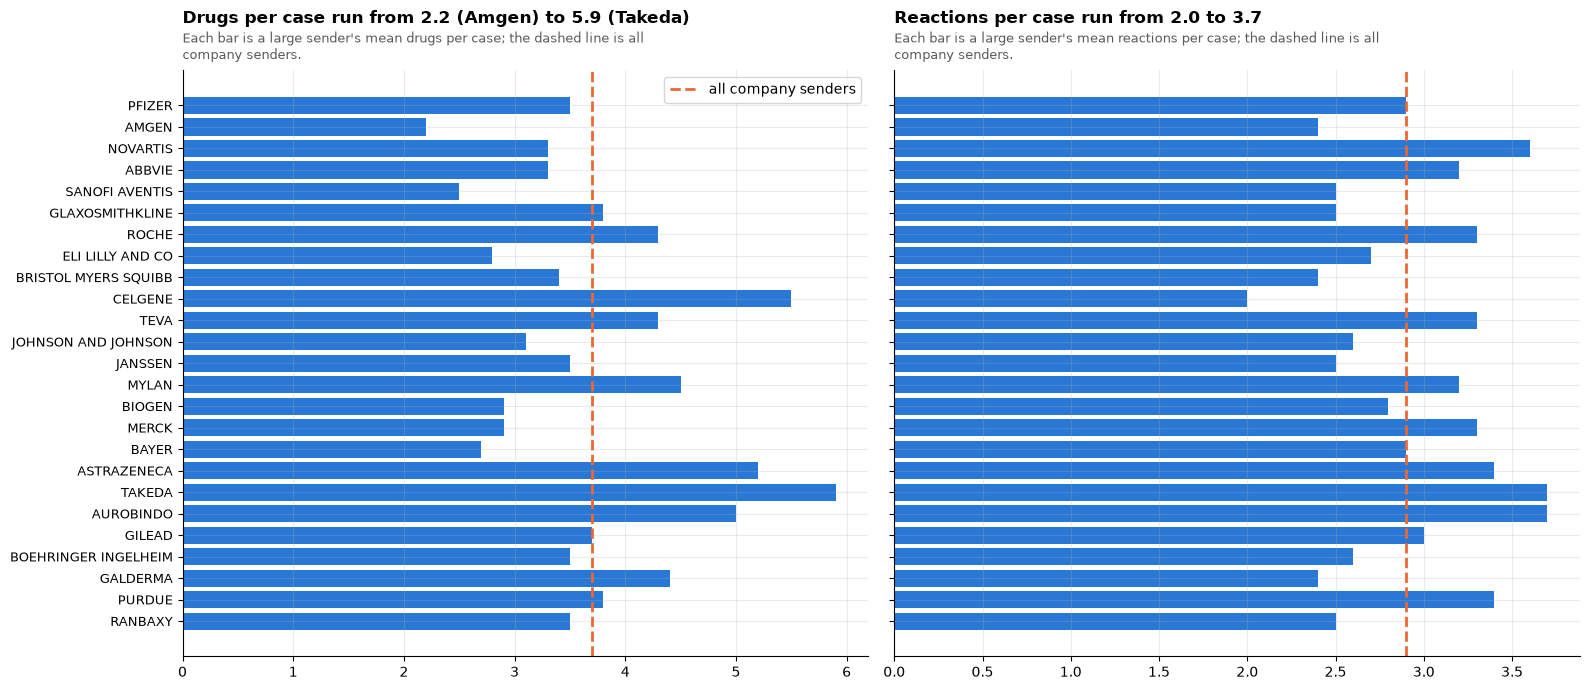

In [7]:
# drugs and reactions per case by sender: the case-complexity dimension of the fingerprint
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 7), sharey=True)
p2 = prof.iloc[1:][::-1]
a1.barh(p2.index, p2["drugs per case"], color=SERIES[0])
a1.axvline(prof.iloc[0]["drugs per case"], color=SERIES[1], ls="--", label="all company senders")
title(
    a1,
    f"Drugs per case run from {p2['drugs per case'].min():.1f} "
    f"({p2['drugs per case'].idxmin().title()}) to {p2['drugs per case'].max():.1f} "
    f"({p2['drugs per case'].idxmax().title()})",
    "Each bar is a large sender's mean drugs per case; the dashed line is all company senders.",
)
a1.legend()
a1.tick_params(axis="y", labelsize=9)
a2.barh(p2.index, p2["reactions per case"], color=SERIES[0])
a2.axvline(prof.iloc[0]["reactions per case"], color=SERIES[1], ls="--")
title(
    a2,
    f"Reactions per case run from {p2['reactions per case'].min():.1f} to "
    f"{p2['reactions per case'].max():.1f}",
    "Each bar is a large sender's mean reactions per case; the dashed line is all company senders.",
)
plt.tight_layout()
plt.show()

### 1e · Where the cases originate: the `mfr_num` sender identifier

In the FAERS era most company case numbers follow the E2B pattern `CC-ORGANISATION-NUMBER`, where `CC` is the country of the originating safety database. Parsing it (as `_T` columns, raw untouched) gives an origin country that is independent of `occr_country`, and an organisation string that sometimes differs from `mfr_sndr` (licensing partners, merged companies, legacy database names).

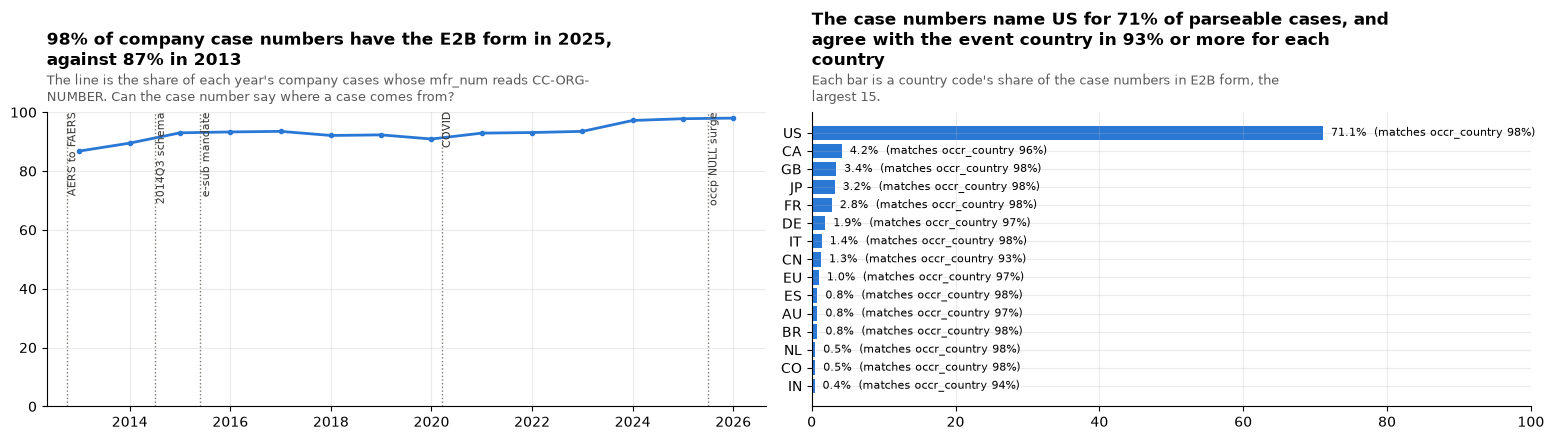

In [8]:
con.execute(r"""create or replace temp view sender_T as
select *, regexp_matches(mfr_num, '^[A-Z]{2}-.+-.+$') as mfr_num_e2b_T,
  split_part(mfr_num, '-', 1) as mfr_num_country_T,
  split_part(mfr_num, '-', 2) as mfr_num_org_T
from case_latest_T where era_T='faers' and rept_cod<>'DIR'""")
cov = q(
    "select init_year_T, round(100.0*count(*) filter (where mfr_num_e2b_T)/count(*),1) pct_e2b_format, count(distinct mfr_num_org_T) orgs from sender_T where init_year_T between 2013 and 2026 group by 1 order by 1"
)
cc = q("""select mfr_num_country_T cc, count(*) n, round(100.0*count(*)/sum(count(*)) over(),1) pct,
  round(100.0*count(*) filter (where occr_country = mfr_num_country_T)/count(*),1) pct_same_as_occr_country
from sender_T where mfr_num_e2b_T group by 1 order by 2 desc limit 15""")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 4.5))
a1.plot(cov.init_year_T, cov.pct_e2b_format, marker="o", ms=3)
a1.set_ylim(0, 100)
title(
    a1,
    f"{cov.pct_e2b_format.iloc[-2]:.0f}% of company case numbers have the E2B form in "
    f"{cov.init_year_T.iloc[-2]:.0f}, against {cov.pct_e2b_format.iloc[0]:.0f}% in "
    f"{cov.init_year_T.iloc[0]:.0f}",
    "The line is the share of each year's company cases whose mfr_num reads CC-ORG-NUMBER.",
    "Can the case number say where a case comes from?",
)
mark_years(a1)
a2.barh(cc.cc[::-1], cc.pct[::-1], color=SERIES[0])
title(
    a2,
    f"The case numbers name {cc.cc.iloc[0]} for {cc.pct.iloc[0]:.0f}% of parseable cases, and agree "
    f"with the event country in {cc.pct_same_as_occr_country.min():.0f}% or more for each country",
    "Each bar is a country code's share of the case numbers in E2B form, the largest 15.",
)
for y, (p, s) in enumerate(zip(cc.pct[::-1], cc.pct_same_as_occr_country[::-1], strict=True)):
    a2.text(p, y, f"  {p:.1f}%  (matches occr_country {s:.0f}%)", va="center", fontsize=8)
a2.set_xlim(0, 100)
plt.tight_layout()
plt.show()

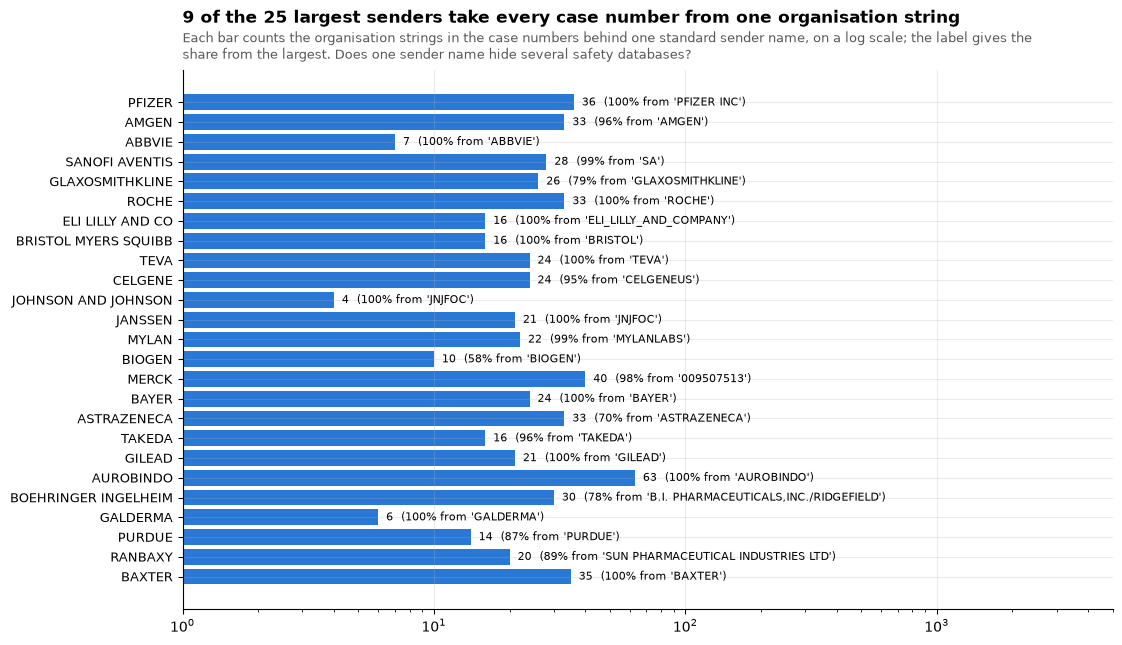

In [9]:
# organisation in mfr_num vs the standardised mfr_sndr: how many databases feed each sender name
org = q("""select mfr_sndr, count(distinct mfr_num_org_T) n_orgs, count(*) cases,
  round(100.0*max(cnt)/count(*),1) pct_from_largest_org, arg_max(mfr_num_org_T, cnt) largest_org
from (select mfr_sndr, mfr_num_org_T, count(*) over (partition by mfr_sndr, mfr_num_org_T) cnt from sender_T where mfr_num_e2b_T)
group by 1 order by 3 desc limit 25""")
fig, ax = plt.subplots(figsize=(12, 7))
ax.barh(org.mfr_sndr[::-1], org.n_orgs[::-1], color=SERIES[0])
ax.set_xscale("log")
single = int((org.pct_from_largest_org == 100).sum())
title(
    ax,
    f"{single} of the 25 largest senders take every case number from one organisation string",
    "Each bar counts the organisation strings in the case numbers behind one standard sender name, "
    "on a log scale; the label gives the share from the largest.",
    "Does one sender name hide several safety databases?",
)
for y, (n, p, o) in enumerate(
    zip(org.n_orgs[::-1], org.pct_from_largest_org[::-1], org.largest_org[::-1], strict=True)
):
    ax.text(n, y, f"  {n}  ({p:.0f}% from '{o}')", va="center", fontsize=8)
ax.set_xlim(1, 5000)
ax.tick_params(axis="y", labelsize=9)
plt.show()

### 1f · Legacy era: the same question before FDA standardised sender names

In AERS the `mfr_sndr` field is free text. A crude normalisation (`mfr_sndr_norm_T`: upper-case, strip punctuation, spaces and legal or departmental suffixes) shows how much of the apparent sender diversity is spelling.

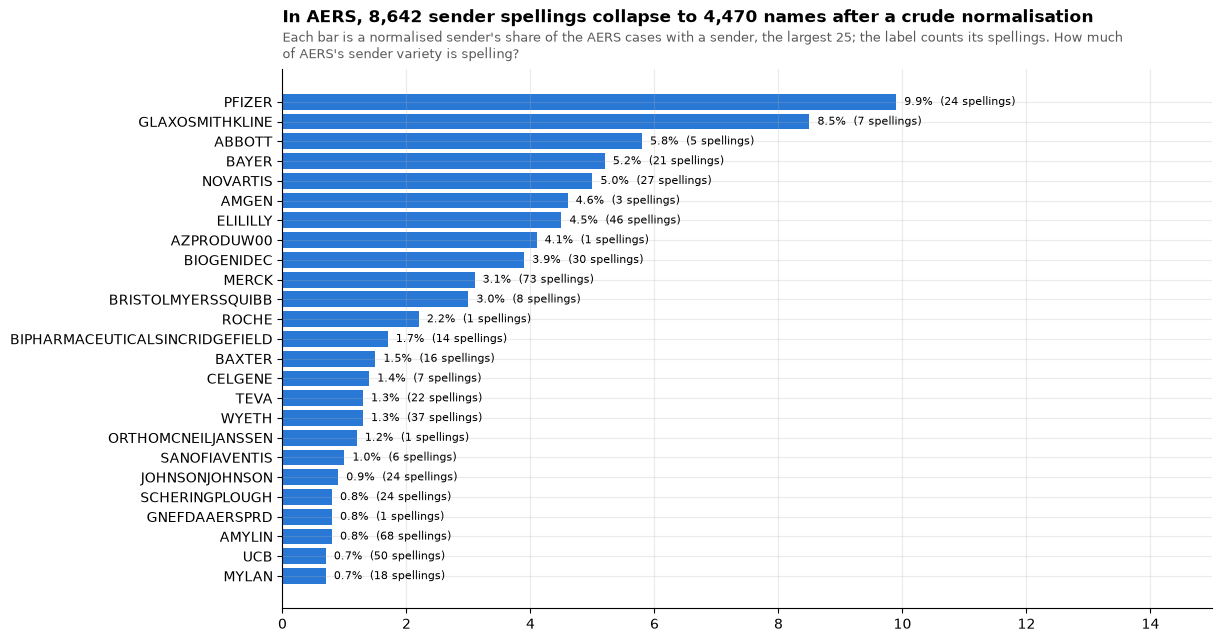

,mfr_sndr_norm_T,spellings,cases,pct
0,PFIZER,24,274599,9.9
1,GLAXOSMITHKLINE,7,235715,8.5
2,ABBOTT,5,159663,5.8
3,BAYER,21,144634,5.2
4,NOVARTIS,27,139827,5.0
5,AMGEN,3,127254,4.6
6,ELILILLY,46,125821,4.5
7,AZPRODUW00,1,113154,4.1
8,BIOGENIDEC,30,108744,3.9
9,MERCK,73,85988,3.1


In [10]:
con.execute(r"""create or replace temp view legacy_sender_T as
select *, regexp_replace(regexp_replace(upper(mfr_sndr), '[^A-Z0-9]', '', 'g'),
   '(INCORPORATED|INC|LTD|LIMITED|LLC|CORPORATION|CORP|COMPANY|CO|PHARMACEUTICALS|PHARMACEUTICAL|PHARMA|HEALTHCARE|LABORATORIES|LABS|SAFETY|USA|US|GMBH|SA|AG|AND|PLC|DIVISION|HUMANHEALTH)+$', '') as mfr_sndr_norm_T
from case_latest_T where era_T='legacy'""")
leg = q("""select mfr_sndr_norm_T, count(distinct mfr_sndr) spellings, count(*) cases, round(100.0*count(*)/sum(count(*)) over(),1) pct
from legacy_sender_T where mfr_sndr is not null group by 1 order by 3 desc limit 25""")
tot = q(
    "select count(distinct mfr_sndr) raw, count(distinct mfr_sndr_norm_T) norm from legacy_sender_T where mfr_sndr is not null"
).iloc[0]
fig, ax = plt.subplots(figsize=(12, 7))
ax.barh(leg.mfr_sndr_norm_T[::-1], leg.pct[::-1], color=SERIES[0])
for y, (p, s) in enumerate(zip(leg.pct[::-1], leg.spellings[::-1], strict=True)):
    ax.text(p, y, f"  {p:.1f}%  ({s} spellings)", va="center", fontsize=8)
title(
    ax,
    f"In AERS, {tot.raw:,} sender spellings collapse to {tot.norm:,} names after a crude "
    "normalisation",
    "Each bar is a normalised sender's share of the AERS cases with a sender, the largest 25; the "
    "label counts its spellings.",
    "How much of AERS's sender variety is spelling?",
)
ax.set_xlim(0, 15)
plt.show()
leg

### 1g · Why they send: the obligation behind each path

The sender population is shaped by law, not by who happens to notice an adverse event. Reporting to FAERS is mandatory for the holder of a marketing authorisation and voluntary for everyone else; whoever a patient or clinician tells first determines the path the case takes.

| who | what they must send | required? | where the requirement comes from |
|---|---|---|---|
| Holders of an approved NDA or ANDA (brand and generic drugs) | 15-day "alert" reports for every **serious and unexpected** (not in the label) adverse experience from **any** source, foreign or domestic, including literature and post-marketing studies (`EXP`); periodic reports (PADER, or PSUR/PBRER with a waiver) of all other domestic spontaneous cases, quarterly for the first 3 years after approval and annually thereafter (`PER`) | mandatory | FD&C Act 505(k); 21 CFR 314.80 (and 314.98 for ANDAs) |
| Holders of a BLA (therapeutic biologics) | the same 15-day plus periodic structure | mandatory | PHS Act 351; 21 CFR 600.80 |
| Marketers of prescription drugs **without** an approved application, including 503B outsourcing facilities | 15-day reports only, no periodic reports | mandatory | 21 CFR 310.305; FD&C Act 503B(b)(5) |
| Manufacturers, packers and distributors of **nonprescription** (OTC monograph) drugs | serious adverse events within 15 business days | mandatory since 22 Dec 2007 | FD&C Act section 760, added by the Dietary Supplement and Nonprescription Drug Consumer Protection Act of 2006 |
| Applicants for **combination products** with a device constituent (autoinjectors, prefilled syringes, inhalers, patches) | in addition to the above, device-style reports: 5-day reports and 30-day malfunction reports (`5DAY`, `30DAY`) | mandatory since 31 Jul 2020 | 21 CFR Part 4 subpart B (4.100 to 4.105), the combination product post-marketing safety reporting rule |
| Non-applicants that handle the product: distributors, repackagers, relabelers, contract manufacturers | forward any adverse experience to the applicant within 5 calendar days, or report it to FDA themselves | mandatory | 21 CFR 314.80(c)(1)(iii) |
| Health professionals (physicians, pharmacists, nurses) | MedWatch Form 3500 | voluntary at federal level (hospital policy and accreditation standards may require internal reporting, not FDA reporting) | FDA MedWatch programme, 1993 |
| Consumers and caregivers | MedWatch Form 3500B or the online form | voluntary | FDA MedWatch programme |
| Lawyers | usually via the company (product-liability claims are adverse-experience information the applicant must review) | not reporters in their own right; the company's obligation applies | 21 CFR 314.80(b) |

Three consequences visible in the data:

- **Companies must review everything that reaches them.** 21 CFR 314.80(b) obliges the applicant to "promptly review all adverse drug experience information obtained or otherwise received ... from any source, foreign or domestic", including call centres, patient support programmes, market research, lawsuits, literature and social media. That is why a consumer who phones a company becomes a company-path case, and why the company path is over 95% of volume even though the consumer is the reporter for almost half of it.
- **Seriousness and expectedness set the clock, not the source.** Serious and unexpected cases go in 15 days (`EXP`); everything else waits for the periodic report (`PER`). A sender's EXP share therefore reflects how broad its labels are and how old its products are (periodic frequency drops to annual after 3 years), which is what the fingerprint in 1d shows: Galderma at 2% EXP is a consumer, non-serious, labelled-event population; Aurobindo and Mylan at 86 to 90% EXP send almost nothing but the mandatory alerts because, as generic houses, they are not the ones running patient programmes.
- **Two rule changes are visible as steps.** The electronic-submission requirement (21 CFR 314.80(g), 600.80(h)) took effect on 10 June 2015; e_sub was already at 90% so the step is small. The combination-product rule of 31 July 2020 created the `30DAY` and `5DAY` codes, sent by companies with device-delivered products (Pfizer, GSK, J&J, Regeneron, ViiV), which is the discontinuity in notebook 01.

What is **not** in FAERS: vaccines (VAERS), device-only events (MAUDE), dietary supplements and cosmetics (CAERS), and adverse events in IND clinical trials, which go to the IND under 21 CFR 312.32, not to FAERS. Only post-marketing studies with a reasonable possibility of causation enter FAERS, as `SDY` reporter-source cases.

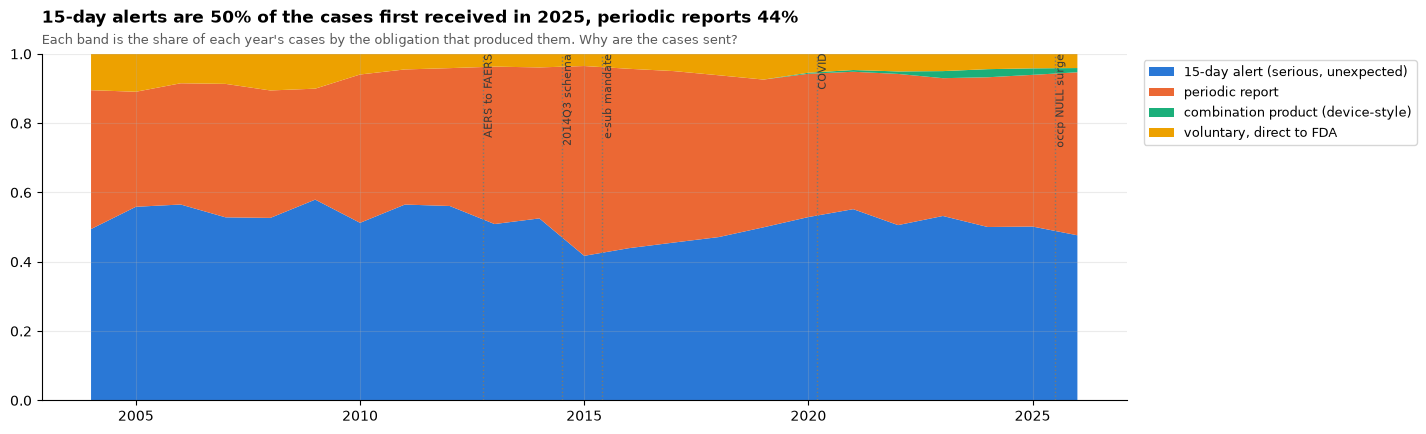

init_year_T,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
obligation_T,,,,,,,,,,,,,,,,,,,,,,,
"15-day alert (serious, unexpected)",101383,128960,138950,140445,163750,196215,247972,313559,391838,392676,457879,494322,519503,567601,668206,710338,764305,857120,766234,724432,655040,653360,320826
periodic report,82164,76616,86003,102395,114343,108440,207143,216361,277857,350490,379871,648986,612028,616428,662014,606166,597436,615808,660796,541306,565676,570110,316715
combination product (device-style),0,0,0,0,0,0,0,0,0,0,1,0,1,9,39,111,4308,7868,10897,27776,30581,24448,8221
"voluntary, direct to FDA",21474,25224,20841,23007,32817,33971,28777,24896,28698,28367,34029,41477,50857,61908,87480,105320,78503,72246,76694,67643,57707,54371,27504


In [11]:
# obligation class by year of first receipt: the legal reason each case exists
ob = q("""select init_year_T,
  case when rept_cod='EXP' then '15-day alert (serious, unexpected)' when rept_cod='PER' then 'periodic report'
       when rept_cod in ('30DAY','5DAY') then 'combination product (device-style)' when rept_cod='DIR' then 'voluntary, direct to FDA' else 'unknown' end obligation_T,
  count(*) n from case_latest_T where init_year_T between 2004 and 2026 group by all order by 1""")
po = ob.pivot(index="init_year_T", columns="obligation_T", values="n").fillna(0)
order = [
    "15-day alert (serious, unexpected)",
    "periodic report",
    "combination product (device-style)",
    "voluntary, direct to FDA",
]
po = po[[c for c in order if c in po.columns]]
share = po.div(po.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.stackplot(
    share.index,
    *[share[c] for c in share.columns],
    labels=share.columns,
    colors=SERIES[: len(share.columns)],
)
ax.set_ylim(0, 1)
year = share.index.max() - 1
title(
    ax,
    f"15-day alerts are {100 * share.iloc[:, 0][year]:.0f}% of the cases first received in {year}, "
    f"periodic reports {100 * share.iloc[:, 1][year]:.0f}%",
    "Each band is the share of each year's cases by the obligation that produced them.",
    "Why are the cases sent?",
)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
mark_years(ax)
plt.show()
po.astype(int).T

### Answer

**Who sends:** pharmaceutical and biologics companies, because the law makes the marketing-authorisation holder responsible for forwarding every adverse experience that reaches it. They account for over 95% of cases in every year since 2013 (1a, 1g). FDA itself is the sender of record for the remaining 4 to 8%, the voluntary MedWatch reports that consumers and clinicians file directly (`FDA-CTU`).

**How many:** roughly 500 to 950 company sender names are active in a given FAERS-era year, but only 20 to 30 of them send more than 10,000 cases, and those carry about half of all company-path cases; the top 50 carry 80 to 94% (1b). The companies are stable: the same 15 or so have been the largest senders every year since 2013, with share shifting as portfolios change (1c). The names are not: from 2024Q4 FDA's standardised sender list starts splitting large senders across two spellings and flipping between them quarter by quarter, so any sender-level analysis after 2024 needs a `mfr_sndr_norm_T` mapping before counting (1c, second chart). FDA standardises `mfr_sndr` in the FAERS era; in the legacy era 8,642 raw strings collapse to 4,470 after a crude normalisation and the top 25 alone hide hundreds of spellings (1f).

**Why it matters for a comparator:** senders are not interchangeable. Their case mix differs by a factor of ten on the fraction that are consumer-reported (Celgene 10%, Galderma 96%), by three on the fraction that are 15-day alerts, by three on US share, and by three on follow-up rate (1d). A disproportionality background drawn from "all of FAERS" is therefore a weighted average of a few dozen company reporting systems, and any drug whose sender differs from that average in these fingerprints inherits a bias before the drug-event relationship is even examined. The `mfr_num` prefix gives a usable origin country for 87 to 98% of company cases, agreeing with `occr_country` 93 to 98% of the time (1e), and shows which sender names aggregate several safety databases (Biogen 58% from its largest, AstraZeneca 70%, GSK and Boehringer under 80%) versus one (Pfizer, Roche, Teva, Baxter, Galderma at 100%).

**Why they send:** see the table in 1g. In one line: applicants must (21 CFR 314.80 / 600.80 / 310.305, FD&C 760 for OTC, 21 CFR Part 4 for combination products), non-applicants in the supply chain must pass cases to the applicant, and health professionals and consumers may but need not.

## Methods-page cards from this notebook

The cards below are computed by the same functions the release build calls (`src/open_altio/faers/insights/cards`), so the chart data on the methods page is reproducible from this code. Each card is written to `notebooks/out/cards/` (or `$OPEN_ALTIO_INSIGHTS_OUT`) for checking; the release carries them in `methods.json`.

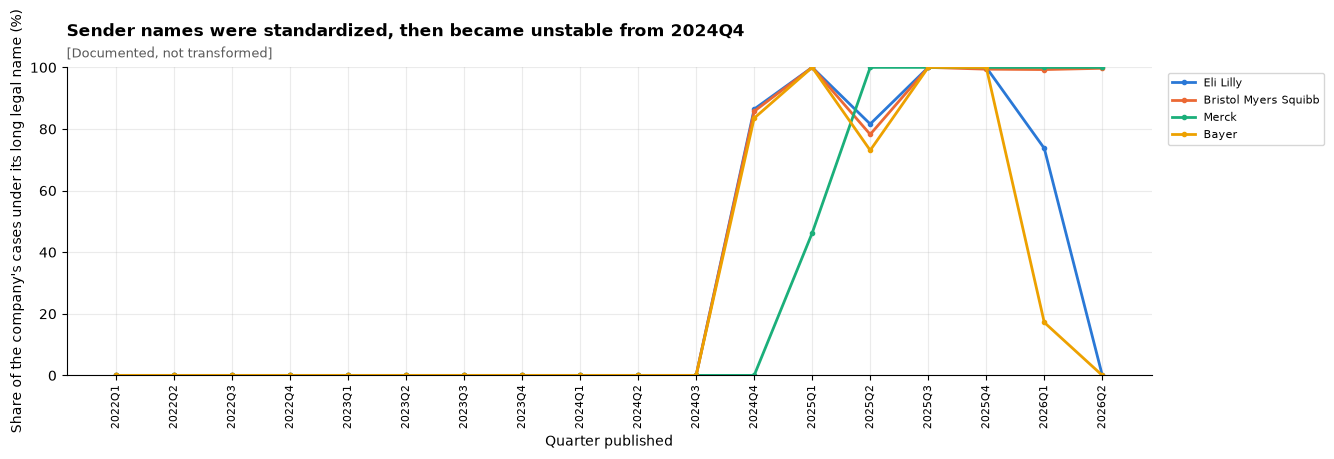

FDA publishes FAERS sender names from a standard list, but from 2024Q4 Lilly, Bristol Myers Squibb and Bayer, and from 2025Q1 Merck, also appear under long legal names, and Lilly and Bayer flip back in 2026. Counting cases by sender after 2024 needs a mapping of these spellings, which we document but do not yet apply.
notebooks/out/cards/90_questions.json


In [12]:
from open_altio.faers.insights.cards import compute_cards
from open_altio.faers.insights.cards.notebook import plot_card, write_cards

cards = compute_cards(con, ["sender_names_unstable"])
for card in cards:
    plot_card(card)
print(write_cards(cards, "90_questions"))